## Exploratory Data Analysis

The purpose of this notebook is to explore the cleaned data and answer our three research questions, which are the following:

1. Which shipping carriers demonstrate the strongest delivery performance, and how do delivery outcomes vary across carriers?

2. What operational, environmental, and transportation-related factors are associated with delivery delays?

3. What factors are associated with customer satisfaction in logistics and supply chain operations?

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

#configure how charts are displayed
%matplotlib inline
sns.set_theme(style="whitegrid")


In [3]:
from google.colab import drive
drive.mount('/content/drive')

df = pd.read_pickle(
    "/content/drive/MyDrive/INSY_6500/data/processed/cleaned_data.pkl"
)

print("Dataset shape:", df.shape)
df.head()

Mounted at /content/drive
Dataset shape: (51000, 33)


,shipment_id,tracking_number,order_id,customer_id,customer_name,shipment_type,carrier,status,origin_city,origin_country,...,delivery_attempts,signature_required,customer_satisfaction_score,delay_reason,damage_reported,claim_filed,claim_amount_eur,co2_emissions_kg,is_international,created_at
0,SHP-202300000,TRK564397239452,ORD-1037076,CUST-777297,Max Mensah,Next Day,UPS,Out For Delivery,Berlin,Germany,...,5,False,NaN,Weather,False,True,0.00,83.21,True,2023-10-10 02:48:00
1,SHP-202300001,TRK693936529454,ORD-1083283,CUST-792581,Anna Becker,Standard,DPD,Lost,Dusseldorf,Germany,...,1,True,NaN,Customs Delay,False,True,0.00,6.82,False,2023-06-07 04:38:00
2,SHP-202300002,TRK934047434283,ORD-5222356,CUST-252305,Leon Schmidt,Standard,FedEx,Delivered,Essen,Germany,...,1,False,3.0,Customs Delay,False,False,0.00,29.85,False,2023-07-17 23:37:00
3,SHP-202300003,TRK249392322429,ORD-4467160,CUST-334941,Thomas Mensah,Standard,Amazon Logistics,Out For Delivery,Cologne,Germany,...,2,False,4.0,Traffic,True,False,703.96,84.77,False,2023-01-08 21:43:00
4,SHP-202300004,TRK275611159480,ORD-8925636,CUST-566318,David Wolf,Next Day,Amazon Logistics,Attempted,Bremen,Germany,...,4,False,2.0,Traffic,True,False,0.00,54.08,False,2023-03-22 15:27:00


In [4]:
# doublce check the data
print("Dataset dimensions:", df.shape)
print("\nData types:")
print(df.dtypes)
print("\nMissing values:")
print(df.isnull().sum())
print("\nSummary statistics:")
display(df.describe(include="all").T)

Dataset dimensions: (51000, 33)

Data types:
shipment_id                            object
tracking_number                        object
order_id                               object
customer_id                            object
customer_name                          object
shipment_type                          object
carrier                                object
status                                 object
origin_city                            object
origin_country                         object
destination_city                       object
destination_country                    object
package_weight_kg                     float64
package_dimensions_cm                  object
declared_value_eur                    float64
shipping_cost_eur                     float64
insurance_cost_eur                    float64
pickup_date                            object
estimated_delivery_date                object
actual_delivery_date                   object
warehouse_id                       

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
shipment_id,51000,51000,SHP-202300000,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tracking_number,51000,51000,TRK564397239452,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
order_id,51000,50854,ORD-9986957,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
customer_id,51000,49595,CUST-320331,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
customer_name,51000,400,Anna Boateng,167,NaN,NaN,NaN,NaN,NaN,NaN,NaN
shipment_type,51000,7,Freight,7376,NaN,NaN,NaN,NaN,NaN,NaN,NaN
carrier,51000,9,Deutsche Post,5788,NaN,NaN,NaN,NaN,NaN,NaN,NaN
status,51000,8,Delivered,15374,NaN,NaN,NaN,NaN,NaN,NaN,NaN
origin_city,51000,15,Dusseldorf,3464,NaN,NaN,NaN,NaN,NaN,NaN,NaN
origin_country,51000,1,Germany,51000,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [5]:
print("Numerical variables:")
display(df.describe().T)

print("\nCategorical variables:")
display(df.describe(include="object").T)

Numerical variables:


,count,mean,min,25%,50%,75%,max,std
package_weight_kg,50885.0,28.180624,0.0,12.63,24.98,37.53,4528.749548,82.495916
declared_value_eur,51000.0,2506.131234,10.15,1255.565,2501.34,3751.9675,4999.88,1441.828583
shipping_cost_eur,50913.0,52.600729,0.0,25.3,47.08,68.69,8452.892707,154.773015
insurance_cost_eur,49502.0,5.020535,0.0,0.0,0.0,9.52,25.0,7.658701
distance_km,51000.0,750.910647,5.0,377.0,753.0,1123.0,1500.0,431.670611
delivery_attempts,51000.0,3.007667,1.0,2.0,3.0,4.0,5.0,1.416555
customer_satisfaction_score,27235.0,3.008665,1.0,2.0,3.0,4.0,5.0,1.414161
claim_amount_eur,51000.0,374.108322,0.0,0.0,0.0,0.0,4999.39,1050.64432
co2_emissions_kg,51000.0,50.00452,0.1,24.9175,50.13,75.04,100.0,28.822865
created_at,51000,2023-06-30 20:07:29.892941312,2023-01-01 00:00:00,2023-04-01 01:52:15,2023-07-01 08:35:30,2023-10-01 05:16:00,2023-12-28 23:57:00,NaN



Categorical variables:


,count,unique,top,freq
shipment_id,51000,51000,SHP-202300000,1
tracking_number,51000,51000,TRK564397239452,1
order_id,51000,50854,ORD-9986957,3
customer_id,51000,49595,CUST-320331,3
customer_name,51000,400,Anna Boateng,167
shipment_type,51000,7,Freight,7376
carrier,51000,9,Deutsche Post,5788
status,51000,8,Delivered,15374
origin_city,51000,15,Dusseldorf,3464
origin_country,51000,1,Germany,51000


## 1. Carrier Delivery Performance

This section examines delivery outcomes across shipping carriers. We will compare shipment volumes and delivery status distributions to identify differences in carrier performance. The analysis will focus on the number of shipments handled by each carrier and the percentage of shipments marked as delivered.

,Shipment Count
carrier,
Deutsche Post,5788
GLS,5743
Hermes,5710
DPD,5700
FedEx,5695
DB Schenker,5653
UPS,5606
DHL,5594
Amazon Logistics,5511


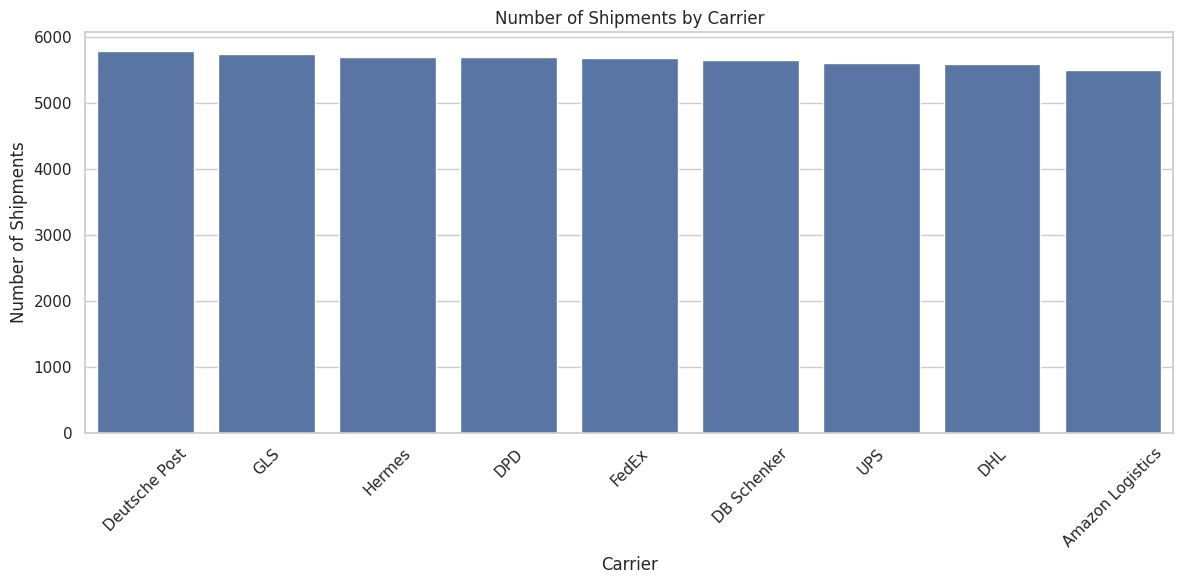

In [6]:
carrier_counts = df["carrier"].value_counts()
display(carrier_counts.to_frame(name="Shipment Count"))

plt.figure(figsize=(12, 6))
sns.barplot(
    x=carrier_counts.index,
    y=carrier_counts.values
)

plt.title("Number of Shipments by Carrier")
plt.xlabel("Carrier")
plt.ylabel("Number of Shipments")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [7]:
carrier_performance = (
    df.assign(is_delivered=df["status"].eq("Delivered"))
      .groupby("carrier")
      .agg(
          total_shipments=("shipment_id", "count"),
          delivered_shipments=("is_delivered", "sum")
      )
)

carrier_performance["delivery_rate_pct"] = (
    carrier_performance["delivered_shipments"]
    / carrier_performance["total_shipments"] * 100
)

carrier_performance = carrier_performance.sort_values(
    "delivery_rate_pct", ascending=False
)

display(carrier_performance.round(2))

,total_shipments,delivered_shipments,delivery_rate_pct
carrier,,,
Hermes,5710,1787,31.30
DB Schenker,5653,1742,30.82
FedEx,5695,1742,30.59
Amazon Logistics,5511,1678,30.45
DHL,5594,1693,30.26
Deutsche Post,5788,1743,30.11
UPS,5606,1663,29.66
GLS,5743,1681,29.27
DPD,5700,1645,28.86


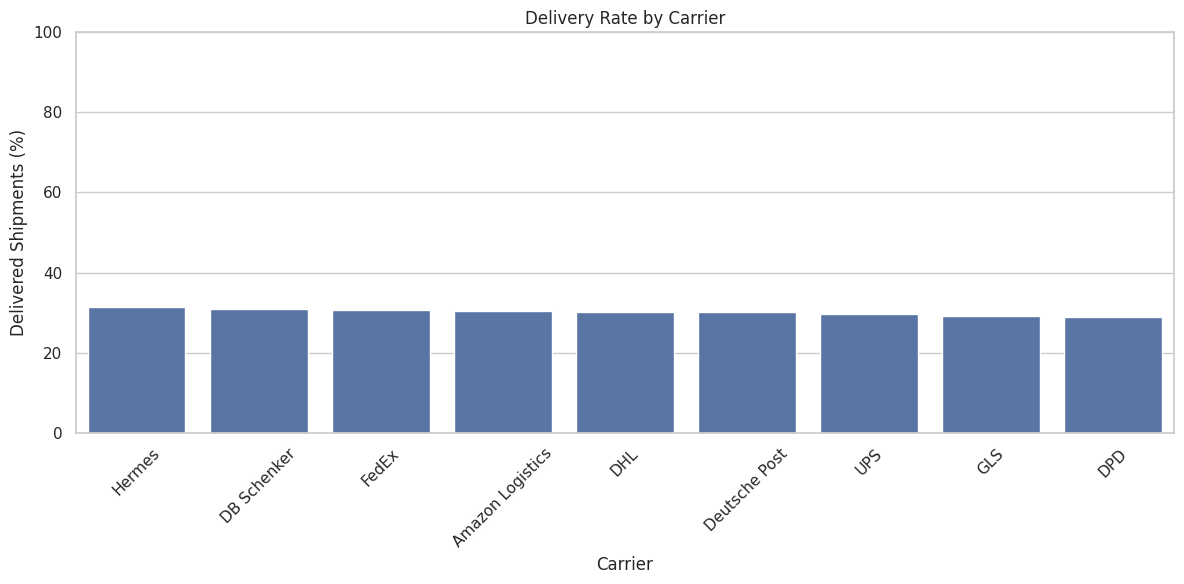

In [8]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=carrier_performance.reset_index(),
    x="carrier",
    y="delivery_rate_pct"
)

plt.title("Delivery Rate by Carrier")
plt.xlabel("Carrier")
plt.ylabel("Delivered Shipments (%)")
plt.xticks(rotation=45)
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

### Delivery Status Distribution by Carrier

To better understand differences in carrier performance, this analysis compares the distribution of all shipment statuses across carriers. This helps identify whether certain carriers have higher proportions of unsuccessful, delayed, or incomplete deliveries.

In [9]:
status_by_carrier = pd.crosstab(
    df["carrier"],
    df["status"],
    normalize="index"
) * 100

display(status_by_carrier.round(2))

status,Attempted,Delivered,Failed,In Transit,Lost,Out For Delivery,Pending,Returned
carrier,,,,,,,,
Amazon Logistics,10.16,30.45,9.85,10.42,9.76,10.45,9.64,9.27
DB Schenker,9.75,30.82,10.45,10.01,9.22,9.98,9.89,9.89
DHL,9.69,30.26,10.62,10.05,9.85,9.67,10.26,9.60
DPD,9.54,28.86,10.11,10.47,10.09,9.88,10.47,10.58
Deutsche Post,9.78,30.11,9.78,10.33,10.25,9.78,10.54,9.43
FedEx,9.85,30.59,9.92,10.08,10.17,9.57,9.90,9.92
GLS,9.84,29.27,10.19,9.72,10.33,10.41,10.27,9.98
Hermes,9.42,31.30,9.72,9.84,9.95,10.54,8.91,10.32
UPS,10.04,29.66,10.01,10.38,9.90,9.65,10.06,10.29


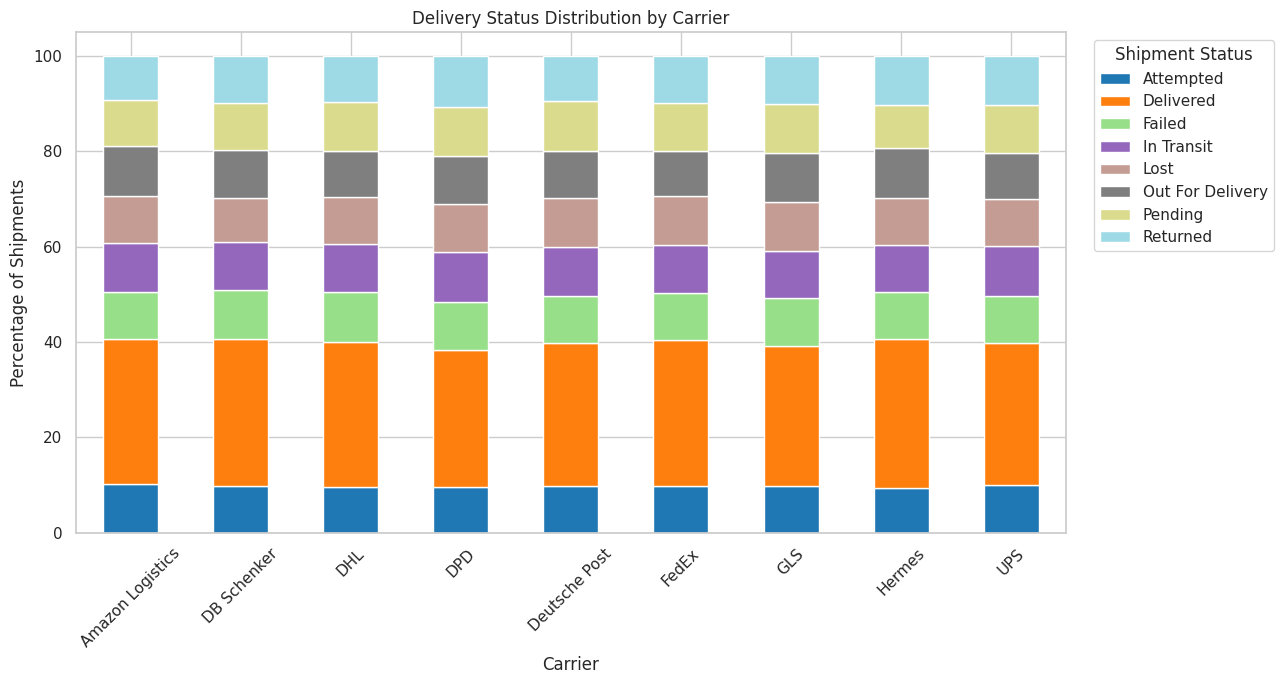

In [10]:
status_by_carrier.plot(
    kind="bar",
    stacked=True,
    figsize=(13, 7),
    colormap="tab20"
)

plt.title("Delivery Status Distribution by Carrier")
plt.xlabel("Carrier")
plt.ylabel("Percentage of Shipments")
plt.xticks(rotation=45)
plt.legend(title="Shipment Status", bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()

### Statistical Analysis: Carrier and Delivery Status

A chi-square test of independence is used to examine whether shipment delivery status is associated with the shipping carrier. This test helps determine whether the observed differences in delivery status distributions are statistically significant.

In [11]:
from scipy.stats import chi2_contingency
import numpy as np

#create a contingency table
contingency_table = pd.crosstab(
    df["carrier"],
    df["status"]
)

#perform chi-square test
chi2, p_value, dof, expected = chi2_contingency(
    contingency_table
)

#calculate Cramer's V
n = contingency_table.to_numpy().sum()
min_dimension = min(contingency_table.shape) - 1

cramers_v = np.sqrt(
    chi2 / (n * min_dimension)
)

print(f"Chi-square statistic: {chi2:.2f}")
print(f"Degrees of freedom: {dof}")
print(f"P-value: {p_value:.6f}")
print(f"Cramer's V: {cramers_v:.4f}")

Chi-square statistic: 50.14
Degrees of freedom: 56
P-value: 0.695047
Cramer's V: 0.0119


In [12]:
alpha = 0.05

if p_value < alpha:
    print("There is a statistically significant association between carrier and delivery status.")
else:
    print("There is not enough evidence of an association between carrier and delivery status.")

print(f"Effect size (Cramer's V): {cramers_v:.4f}")

There is not enough evidence of an association between carrier and delivery status.
Effect size (Cramer's V): 0.0119


### Research Question 1: Key Findings

The analysis examined delivery performance across nine shipping carriers using shipment volumes, delivery rates, delivery status distributions, and a chi-square test of independence.

Shipment volumes were relatively **balanced** across carriers. Hermes recorded the highest delivered-status rate at 31.30%, while DPD recorded the lowest at 28.86%. However, the difference between the highest and lowest rates was relatively small.

The chi-square test found **no statistically significant association** between shipping carrier and delivery status (χ² = 50.14, df = 56, p = 0.695). Cramer's V was 0.0119, indicating a negligible association.

Overall, the analysis does not provide sufficient evidence that delivery outcomes differ significantly by carrier. Other operational or environmental factors may be more relevant to understanding delivery performance. **These factors will be explored in the next research question.**

## 2. Factors Associated with Delivery Delays

This section investigates operational, environmental, and transportation-related factors that may be associated with delivery delays. The analysis examines recorded delay reasons, shipment characteristics, transportation distance, delivery attempts, and carbon emissions. The goal is to identify patterns in delivery outcomes and determine which factors may contribute to unsuccessful or delayed shipments.

### Distribution of Delivery Delay Reasons

This analysis examines the frequency and distribution of recorded delay reasons. Identifying the most common reasons provides an initial understanding of the challenges affecting shipment delivery performance.

In [13]:
delay_counts = df["delay_reason"].value_counts()

delay_summary = pd.DataFrame({
    "Shipment Count": delay_counts,
    "Percentage of Recorded Reasons": (
        delay_counts / delay_counts.sum() * 100
    )
})

display(delay_summary.round(2))

print("Shipments with recorded delay reasons:", df["delay_reason"].notna().sum())
print("Shipments with missing delay reasons:", df["delay_reason"].isna().sum())

,Shipment Count,Percentage of Recorded Reasons
delay_reason,,
Recipient Not Available,5588,14.48
Weather,5532,14.33
Vehicle Breakdown,5520,14.30
Strike,5513,14.29
Incorrect Address,5512,14.28
Traffic,5502,14.26
Customs Delay,5425,14.06


Shipments with recorded delay reasons: 38592
Shipments with missing delay reasons: 12408


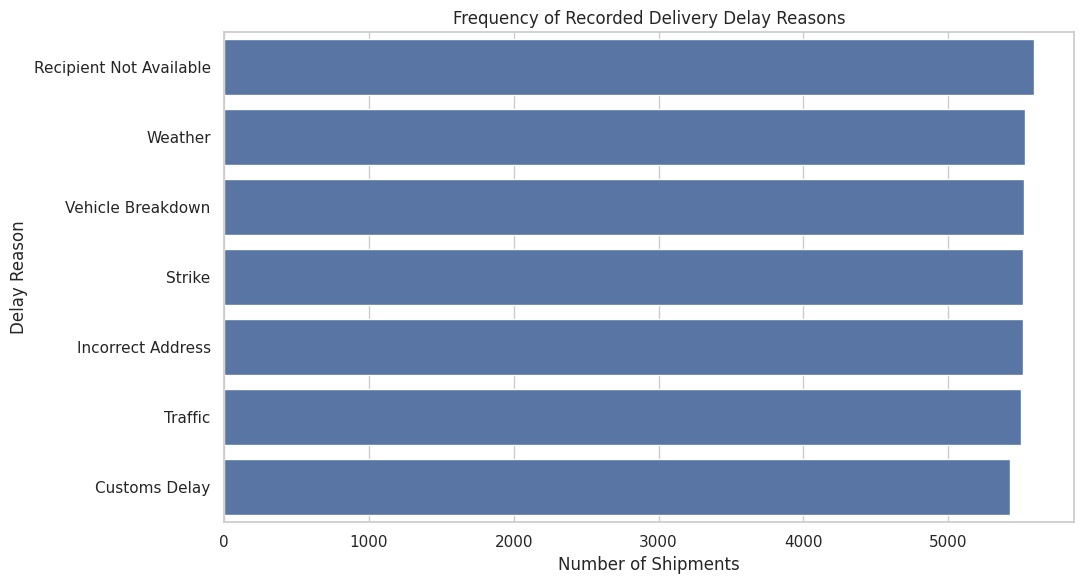

In [14]:
plt.figure(figsize=(11, 6))

sns.countplot(
    data=df,
    y="delay_reason",
    order=df["delay_reason"].value_counts().index
)

plt.title("Frequency of Recorded Delivery Delay Reasons")
plt.xlabel("Number of Shipments")
plt.ylabel("Delay Reason")
plt.tight_layout()
plt.show()

### Delay Reasons Across Shipment Statuses

This analysis compares recorded delay reasons across shipment statuses to identify potential patterns between the reasons for delays and shipment outcomes.

In [15]:
delay_by_status = pd.crosstab(
    df["delay_reason"],
    df["status"]
)

display(delay_by_status)

status,Attempted,Delivered,Failed,In Transit,Lost,Out For Delivery,Pending,Returned
delay_reason,,,,,,,,
Customs Delay,536,1608,543,531,535,549,564,559
Incorrect Address,531,1711,556,565,548,536,549,516
Recipient Not Available,561,1689,563,535,600,523,575,542
Strike,561,1607,568,581,554,556,540,546
Traffic,510,1657,580,576,554,559,542,524
Vehicle Breakdown,536,1617,560,604,566,547,534,556
Weather,544,1710,542,552,557,570,520,537


In [16]:
delay_by_status_pct = pd.crosstab(
    df["delay_reason"],
    df["status"],
    normalize="index"
) * 100

display(delay_by_status_pct.round(2))

status,Attempted,Delivered,Failed,In Transit,Lost,Out For Delivery,Pending,Returned
delay_reason,,,,,,,,
Customs Delay,9.88,29.64,10.01,9.79,9.86,10.12,10.40,10.30
Incorrect Address,9.63,31.04,10.09,10.25,9.94,9.72,9.96,9.36
Recipient Not Available,10.04,30.23,10.08,9.57,10.74,9.36,10.29,9.70
Strike,10.18,29.15,10.30,10.54,10.05,10.09,9.80,9.90
Traffic,9.27,30.12,10.54,10.47,10.07,10.16,9.85,9.52
Vehicle Breakdown,9.71,29.29,10.14,10.94,10.25,9.91,9.67,10.07
Weather,9.83,30.91,9.80,9.98,10.07,10.30,9.40,9.71


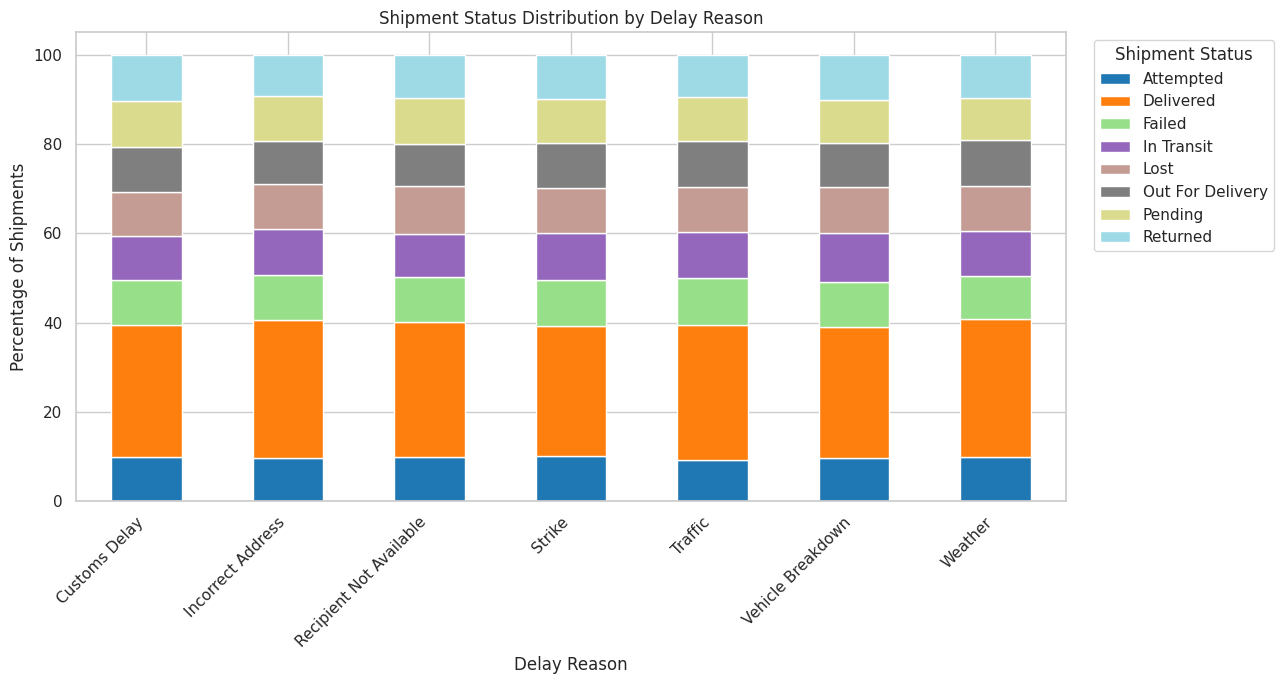

In [17]:
delay_by_status_pct.plot(
    kind="bar",
    stacked=True,
    figsize=(13, 7),
    colormap="tab20"
)

plt.title("Shipment Status Distribution by Delay Reason")
plt.xlabel("Delay Reason")
plt.ylabel("Percentage of Shipments")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Shipment Status", bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()

### Statistical Analysis: Delay Reason and Shipment Status

A chi-square test of independence is used to examine whether recorded delay reasons are associated with shipment status. Only shipments with a recorded delay reason are included in this analysis. Cramer's V is also calculated to measure the strength of the association.

In [18]:
from scipy.stats import chi2_contingency
import numpy as np

# exclude shipments without a recorded delay reason
delay_status_table = pd.crosstab(
    df.loc[df["delay_reason"].notna(), "delay_reason"],
    df.loc[df["delay_reason"].notna(), "status"]
)

chi2, p_value, dof, expected = chi2_contingency(
    delay_status_table
)

n = delay_status_table.to_numpy().sum()
min_dimension = min(delay_status_table.shape) - 1

cramers_v = np.sqrt(chi2 / (n * min_dimension))

print(f"Chi-square statistic: {chi2:.2f}")
print(f"Degrees of freedom: {dof}")
print(f"P-value: {p_value:.6f}")
print(f"Cramer's V: {cramers_v:.4f}")
print(f"Minimum expected frequency: {expected.min():.2f}")

Chi-square statistic: 31.79
Degrees of freedom: 42
P-value: 0.873858
Cramer's V: 0.0117
Minimum expected frequency: 531.23


In [19]:
alpha = 0.05

if p_value < alpha:
    print("There is a statistically significant association between delay reason and shipment status.")
else:
    print("There is not enough evidence of an association between delay reason and shipment status.")

print(f"Effect size (Cramer's V): {cramers_v:.4f}")

There is not enough evidence of an association between delay reason and shipment status.
Effect size (Cramer's V): 0.0117


### Key Findings: Delay Reasons and Shipment Status

The analysis examined seven recorded delivery delay reasons and their relationship with shipment status. **Recipient Not Available** was the most **frequently recorded reason**, accounting for **14.48%** of shipments with a recorded delay reason. However,** the distribution across all seven categories was relatively balanced.**

A chi-square test of independence found no statistically significant association between delay reason and shipment status (χ² = 31.79, df = 42, p = 0.8739). Cramer's V was 0.0117, indicating a negligible association. The minimum expected frequency was 531.23, satisfying the expected-frequency assumption for the test.

Overall, the results suggest that recorded delay reasons do not meaningfully distinguish shipment outcomes in this dataset. Further analysis of operational and transportation-related variables may provide additional insight into delivery performance.

### Operational and Transportation Factors by Shipment Status

This section examines numerical shipment characteristics across delivery statuses. Distance traveled, package weight, delivery attempts, shipping cost, and CO₂ emissions are compared to identify potential differences between shipment outcomes.

In [20]:
numeric_variables = [
    "distance_km",
    "package_weight_kg",
    "delivery_attempts",
    "shipping_cost_eur",
    "co2_emissions_kg"
]

status_summary = (
    df.groupby("status")[numeric_variables]
      .agg(["count", "mean", "median", "std"])
)

display(status_summary.round(2))

distance_km                        package_weight_kg         \
                       count    mean median     std             count   mean   
status                                                                         
Attempted               4990  746.84  747.0  431.69              4982  27.71   
Delivered              15374  750.85  751.0  431.24             15337  29.38   
Failed                  5136  753.17  754.5  433.74              5124  27.79   
In Transit              5173  744.38  743.0  428.56              5162  27.98   
Lost                    5073  743.10  744.0  434.51              5061  27.15   
Out For Delivery        5096  768.19  771.5  430.80              5084  27.47   
Pending                 5098  751.83  760.0  433.44              5091  27.52   
Returned                5060  749.00  754.0  430.07              5044  28.02   

                                delivery_attempts                     \
                 median     std             count  mean median   std   
status                                                                 
Attempted         25.11   61.59              4990  3.01    3.0  1.42   
Delivered         25.19  101.95             15374  3.01    3.0  1.42   
Failed            24.86   81.94              5136  3.00    3.0  1.42   
In Transit        24.96   66.44              5173  3.04    3.0  1.41   
Lost              24.84   59.95              5073  2.98    3.0  1.41   
Out For Delivery  25.13   77.91              5096  3.01    3.0  1.42   
Pending           24.64   61.21              5098  3.01    3.0  1.42   
Returned          24.39   92.00              5060  2.98    3.0  1.41   

                 shipping_cost_eur                       co2_emissions_kg  \
                             count   mean median     std            count   
status                                                                      
Attempted                     4975  52.39  46.28  146.45             4990   
Delivered                    15344  55.35  47.72  195.68            15374   
Failed                        5125  51.11  46.79  132.05             5136   
In Transit                    5166  51.05  47.24  128.58             5173   
Lost                          5068  49.52  46.97  103.10             5073   
Out For Delivery              5090  49.90  47.30  104.27             5096   
Pending                       5090  53.43  47.30  157.98             5098   
Returned                      5055  52.55  45.52  150.33             5060   

                                       
                   mean median    std  
status                                 
Attempted         50.44  50.30  28.80  
Delivered         49.71  49.78  28.85  
Failed            50.31  50.34  28.70  
In Transit        49.49  48.80  28.71  
Lost              50.05  50.64  28.72  
Out For Delivery  50.52  51.02  28.69  
Pending           50.39  50.35  28.75  
Returned          49.74  49.94  29.30

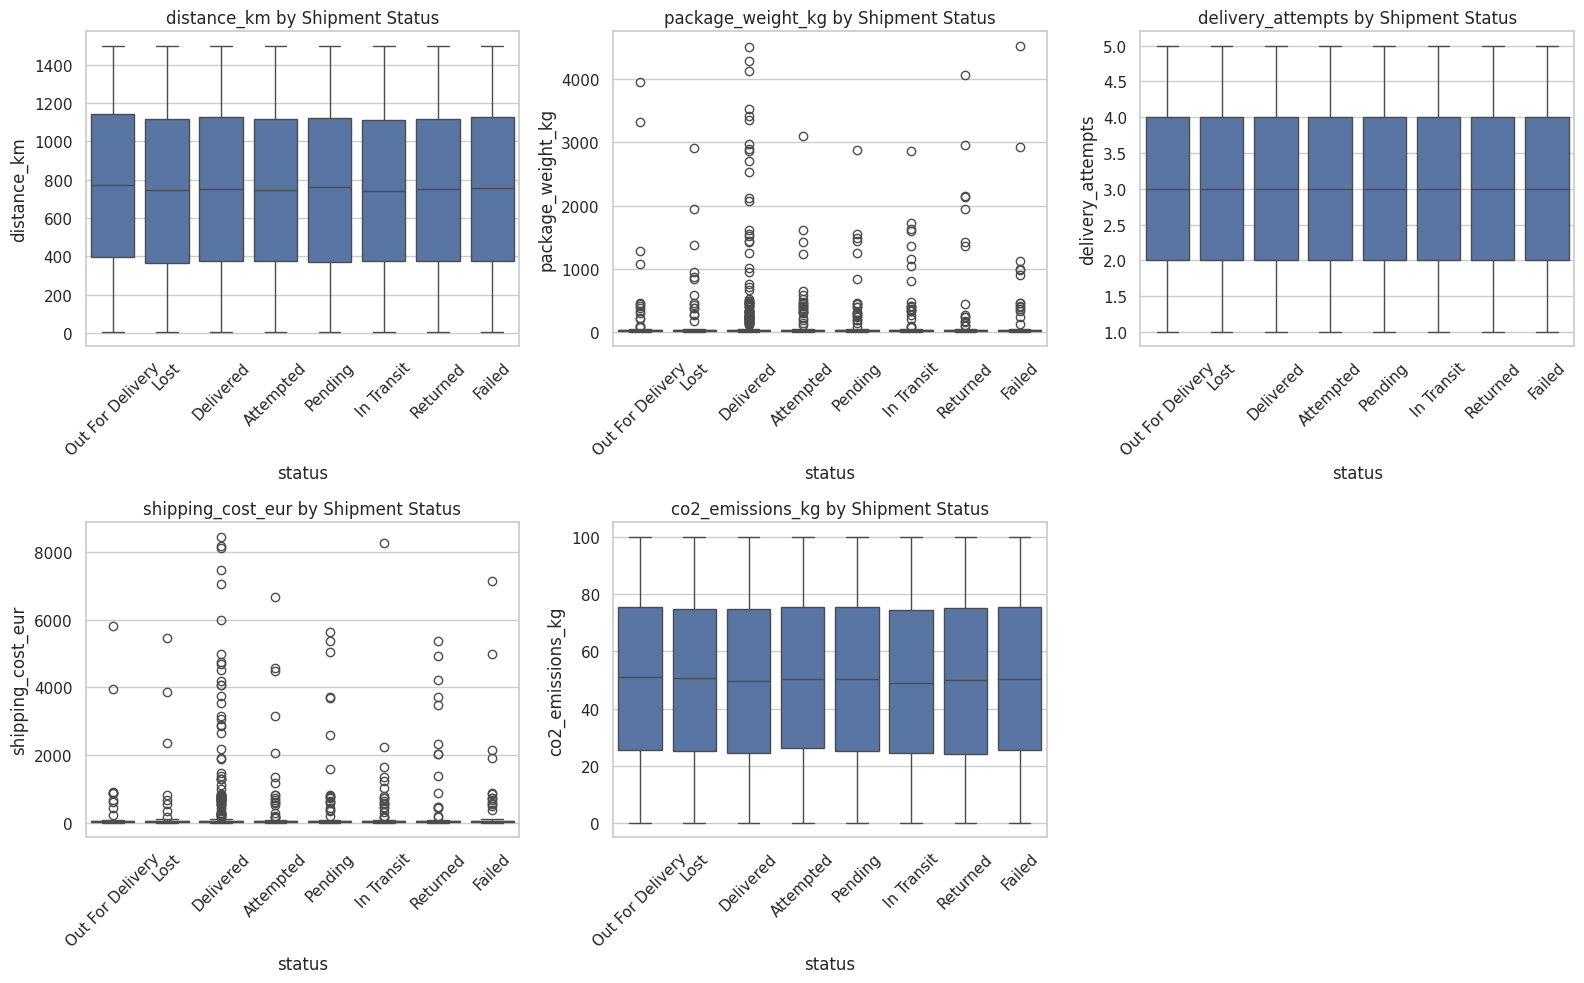

In [21]:
fig, axes = plt.subplots(2, 3, figsize=(16, 10))

for variable, ax in zip(numeric_variables, axes.flatten()):
    sns.boxplot(
        data=df,
        x="status",
        y=variable,
        ax=ax
    )
    ax.set_title(f"{variable} by Shipment Status")
    ax.tick_params(axis="x", rotation=45)

# remove unused sixth subplot
fig.delaxes(axes.flatten()[5])

plt.tight_layout()
plt.show()

### Statistical Analysis: Numerical Factors and Shipment Status

Kruskal-Wallis tests are used to examine whether distance, package weight, delivery attempts, shipping cost, and CO₂ emissions differ across shipment statuses.

This non-parametric approach is appropriate for exploring numerical variables that may contain skewness or outliers. The results will help identify which operational and transportation-related variables show statistically significant differences across shipment outcomes.

In [22]:
from scipy.stats import kruskal

results = []

for variable in numeric_variables:
    groups = [
        group[variable].dropna()
        for _, group in df.groupby("status")
    ]

    statistic, p_value = kruskal(*groups)

    results.append({
        "Variable": variable,
        "Kruskal-Wallis Statistic": statistic,
        "P-value": p_value
    })

kruskal_results = pd.DataFrame(results)

display(kruskal_results.round(6))

,Variable,Kruskal-Wallis Statistic,P-value
0,distance_km,11.685252,0.111396
1,package_weight_kg,6.319973,0.502924
2,delivery_attempts,5.621133,0.584616
3,shipping_cost_eur,3.359648,0.849860
4,co2_emissions_kg,7.939283,0.337978


In [23]:
from statsmodels.stats.multitest import multipletests

kruskal_results["Adjusted P-value"] = multipletests(
    kruskal_results["P-value"],
    method="holm"
)[1]

kruskal_results["Significant"] = (
    kruskal_results["Adjusted P-value"] < 0.05
)

display(kruskal_results.round(6))

,Variable,Kruskal-Wallis Statistic,P-value,Adjusted P-value,Significant
0,distance_km,11.685252,0.111396,0.556981,False
1,package_weight_kg,6.319973,0.502924,1.000000,False
2,delivery_attempts,5.621133,0.584616,1.000000,False
3,shipping_cost_eur,3.359648,0.849860,1.000000,False
4,co2_emissions_kg,7.939283,0.337978,1.000000,False


### Key Findings: Numerical Factors and Shipment Status

The analysis examined five numerical variables across shipment statuses: distance, package weight, delivery attempts, shipping cost, and CO₂ emissions.

Although some differences were observed in the descriptive statistics, the Kruskal-Wallis tests **found no statistically significant differences across shipment status groups for any of the five variables.**

After applying the Holm correction for multiple comparisons, all adjusted p-values remained above the 0.05 significance level. Distance had the lowest adjusted p-value (0.556981), while the other variables had adjusted p-values of 1.000000.

Overall, **the analysis did not find sufficient statistical evidence that these numerical operational and transportation factors differ across shipment statuses.** This does not establish that these factors have no influence on delivery delays, but suggests that further investigation is needed.


### Numerical Factors Across Recorded Delay Reasons

This analysis investigates whether shipment distance, package weight, delivery attempts, shipping cost, and CO₂ emissions differ across recorded delay reasons.

Only shipments with a recorded delay reason are included. Kruskal-Wallis tests are used to compare the numerical distributions across the delay-reason categories.

In [24]:
delay_reason_results = []

for variable in numeric_variables:
    groups = [
        group[variable].dropna()
        for _, group in df[df["delay_reason"].notna()]
            .groupby("delay_reason")
    ]

    statistic, p_value = kruskal(*groups)

    delay_reason_results.append({
        "Variable": variable,
        "Kruskal-Wallis Statistic": statistic,
        "P-value": p_value
    })

delay_reason_results = pd.DataFrame(delay_reason_results)

delay_reason_results["Adjusted P-value"] = multipletests(
    delay_reason_results["P-value"],
    method="holm"
)[1]

delay_reason_results["Significant"] = (
    delay_reason_results["Adjusted P-value"] < 0.05
)

display(delay_reason_results.round(6))

,Variable,Kruskal-Wallis Statistic,P-value,Adjusted P-value,Significant
0,distance_km,9.447735,0.149919,0.703112,False
1,package_weight_kg,2.971554,0.812409,1.000000,False
2,delivery_attempts,2.802845,0.833154,1.000000,False
3,shipping_cost_eur,9.640678,0.140622,0.703112,False
4,co2_emissions_kg,2.355899,0.884233,1.000000,False


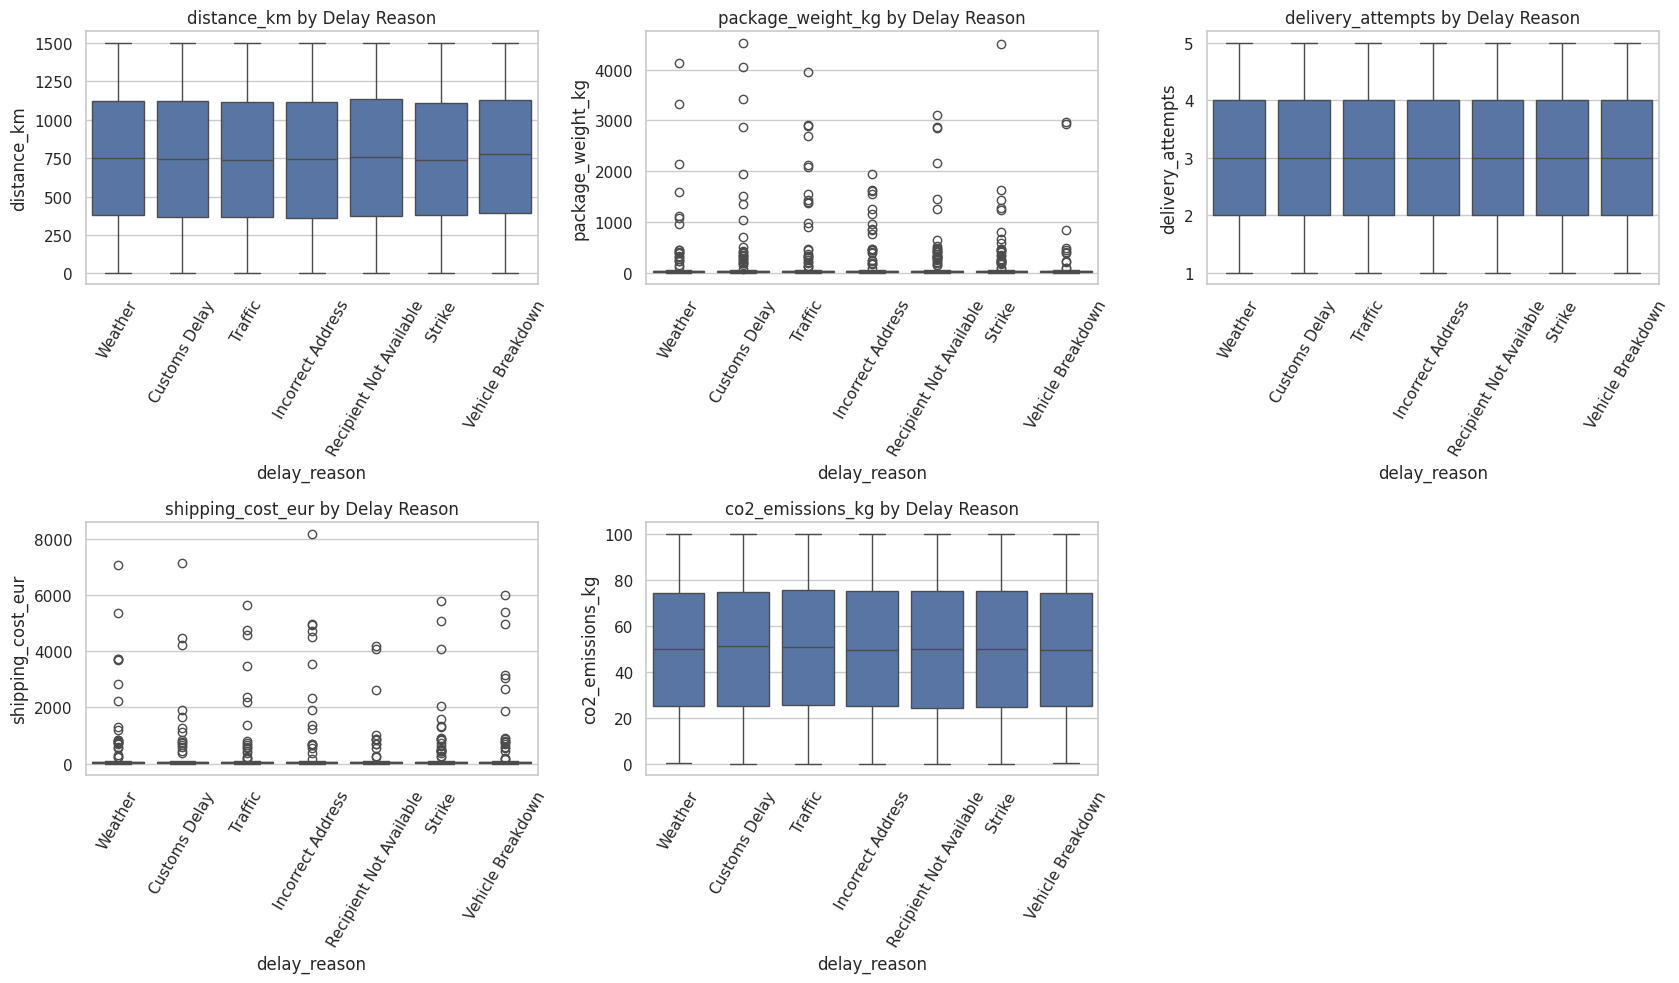

In [25]:
fig, axes = plt.subplots(2, 3, figsize=(17, 10))

for variable, ax in zip(numeric_variables, axes.flatten()):
    sns.boxplot(
        data=df[df["delay_reason"].notna()],
        x="delay_reason",
        y=variable,
        ax=ax
    )

    ax.set_title(f"{variable} by Delay Reason")
    ax.tick_params(axis="x", rotation=60)

fig.delaxes(axes.flatten()[5])

plt.tight_layout()
plt.show()

### Key Findings: Numerical Factors and Recorded Delay Reasons

The analysis examined whether distance, package weight, delivery attempts, shipping cost, and CO₂ emissions differed across the seven recorded delay-reason categories.

The Kruskal-Wallis tests **found no statistically significant differences** for any of the five numerical variables. After applying the Holm correction for multiple comparisons, all adjusted p-values remained above the 0.05 significance level.

Distance and shipping cost had the lowest original p-values (0.149919 and 0.140622, respectively), **but neither result was statistically significant after adjustment.**

Overall, the results do not provide sufficient evidence that the numerical shipment characteristics examined are associated with the recorded delay reasons. The boxplots also show **considerable overlap between the distributions across categories.**

### Categorical Factors and Recorded Delay Reasons

This section examines whether shipping carrier and shipment type are associated with recorded delay reasons. Chi-square tests of independence are used to identify potential relationships between these categorical variables.

In [26]:
categorical_results = []

for variable in ["carrier", "shipment_type"]:
    table = pd.crosstab(
        df.loc[df["delay_reason"].notna(), variable],
        df.loc[df["delay_reason"].notna(), "delay_reason"]
    )

    chi2, p_value, dof, expected = chi2_contingency(table)

    n = table.to_numpy().sum()
    min_dimension = min(table.shape) - 1

    cramers_v = np.sqrt(chi2 / (n * min_dimension))

    categorical_results.append({
        "Variable": variable,
        "Chi-square Statistic": chi2,
        "Degrees of Freedom": dof,
        "P-value": p_value,
        "Cramer's V": cramers_v,
        "Minimum Expected Frequency": expected.min()
    })

categorical_results = pd.DataFrame(categorical_results)

categorical_results["Adjusted P-value"] = multipletests(
    categorical_results["P-value"],
    method="holm"
)[1]

categorical_results["Significant"] = (
    categorical_results["Adjusted P-value"] < 0.05
)

display(categorical_results.round(6))

,Variable,Chi-square Statistic,Degrees of Freedom,P-value,Cramer's V,Minimum Expected Frequency,Adjusted P-value,Significant
0,carrier,45.055662,48,0.594222,0.013949,591.250777,0.938259,False
1,shipment_type,35.989706,36,0.469129,0.012467,754.737381,0.938259,False


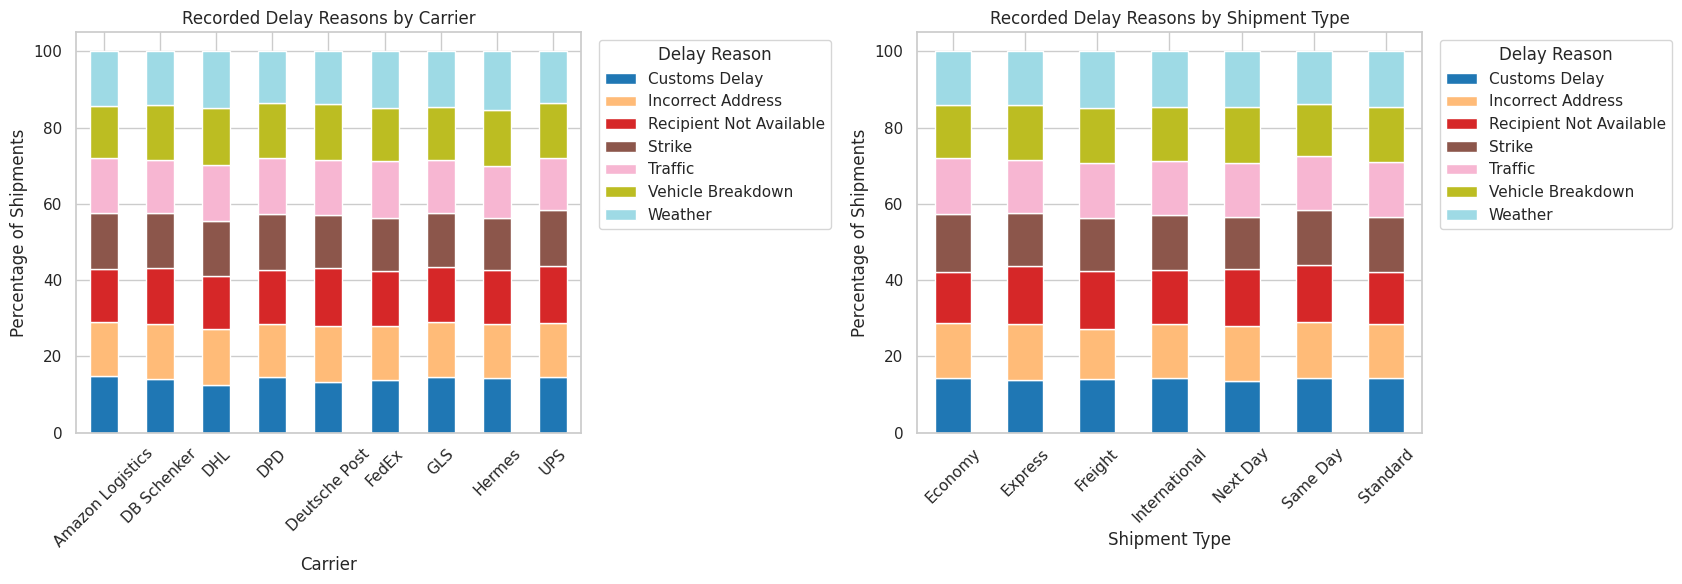

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(17, 6))

for variable, ax in zip(
    ["carrier", "shipment_type"],
    axes
):
    table = pd.crosstab(
        df.loc[df["delay_reason"].notna(), variable],
        df.loc[df["delay_reason"].notna(), "delay_reason"],
        normalize="index"
    ) * 100

    table.plot(
        kind="bar",
        stacked=True,
        ax=ax,
        colormap="tab20"
    )

    ax.set_title(f"Recorded Delay Reasons by {variable.replace('_', ' ').title()}")
    ax.set_xlabel(variable.replace("_", " ").title())
    ax.set_ylabel("Percentage of Shipments")
    ax.tick_params(axis="x", rotation=45)
    ax.legend(title="Delay Reason", bbox_to_anchor=(1.02, 1))

plt.tight_layout()
plt.show()

### Key Findings: Categorical Factors and Recorded Delay Reasons

Overall, the results do not provide sufficient evidence that carrier or shipment type is associated with the distribution of recorded delay reasons in this dataset.

An important limitation is that the pickup, estimated delivery, and actual delivery date fields **contain mixed and ambiguous date formats**. As a result, actual delivery duration and lateness could not be reliably calculated. Therefore, the findings should be interpreted as relationships involving recorded delay reasons and shipment status, rather than direct measurements of delivery delays. Resolving the date-format issue would allow future analysis to examine on-time delivery performance more directly.

## Research Question 3: Factors Associated with Customer Satisfaction

This section examines which factors are associated with customer satisfaction in logistics and supply chain operations. The analysis considers customer satisfaction scores in relation to shipping carrier, shipment status, recorded delay reasons, and numerical shipment characteristics.


In [28]:
# examine customer satisfaction data quality
satisfaction_column = "customer_satisfaction_score"

print("Total records:", len(df))
print("Available satisfaction scores:", df[satisfaction_column].notna().sum())
print("Missing satisfaction scores:", df[satisfaction_column].isna().sum())
print(
    "Missing percentage:",
    round(df[satisfaction_column].isna().mean() * 100, 2),
    "%"
)

print("\nData type:")
print(df[satisfaction_column].dtype)

print("\nDescriptive statistics:")
display(df[satisfaction_column].describe())

print("\nUnique satisfaction scores:")
print(sorted(df[satisfaction_column].dropna().unique()))

Total records: 51000
Available satisfaction scores: 27235
Missing satisfaction scores: 23765
Missing percentage: 46.6 %

Data type:
float64

Descriptive statistics:


,customer_satisfaction_score
count,27235.000000
mean,3.008665
std,1.414161
min,1.000000
25%,2.000000
50%,3.000000
75%,4.000000
max,5.000000



Unique satisfaction scores:
[np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(4.0), np.float64(5.0)]


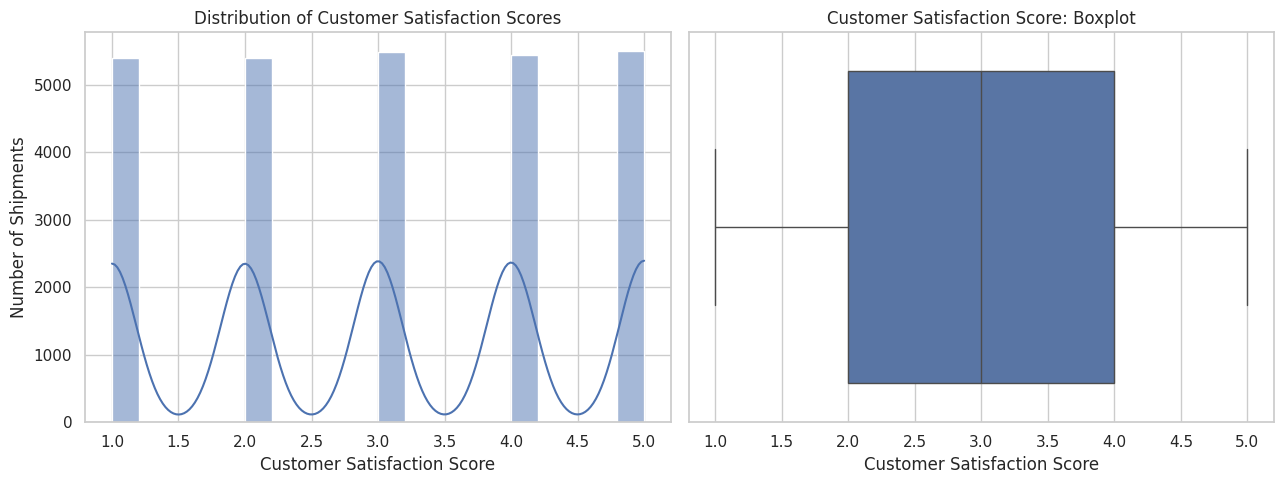

In [29]:
satisfaction_data = df[satisfaction_column].dropna()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.histplot(
    satisfaction_data,
    bins=20,
    kde=True,
    ax=axes[0]
)
axes[0].set_title("Distribution of Customer Satisfaction Scores")
axes[0].set_xlabel("Customer Satisfaction Score")
axes[0].set_ylabel("Number of Shipments")

sns.boxplot(
    x=satisfaction_data,
    ax=axes[1]
)
axes[1].set_title("Customer Satisfaction Score: Boxplot")
axes[1].set_xlabel("Customer Satisfaction Score")

plt.tight_layout()
plt.show()

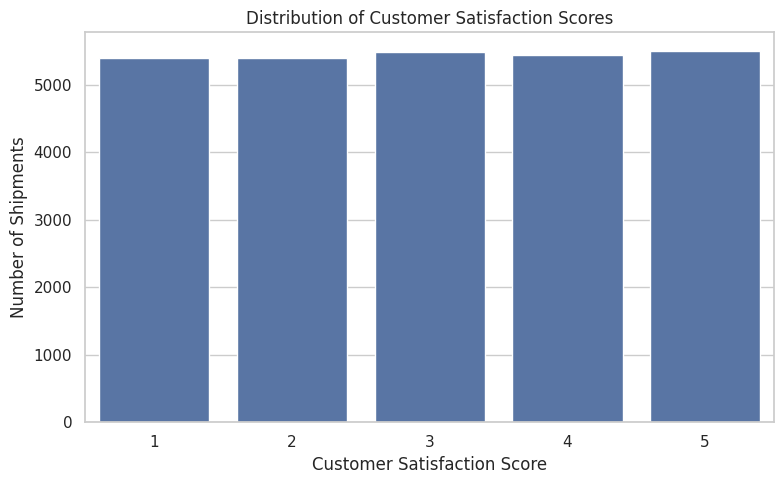

,shipment_count
customer_satisfaction_score,
1,5404
2,5401
3,5487
4,5441
5,5502


In [30]:
satisfaction_counts = (
    satisfaction_data
    .value_counts()
    .reindex([1, 2, 3, 4, 5], fill_value=0)
)

plt.figure(figsize=(8, 5))

sns.barplot(
    x=satisfaction_counts.index,
    y=satisfaction_counts.values
)

plt.title("Distribution of Customer Satisfaction Scores")
plt.xlabel("Customer Satisfaction Score")
plt.ylabel("Number of Shipments")
plt.xticks([0, 1, 2, 3, 4], [1, 2, 3, 4, 5])

plt.tight_layout()
plt.show()

display(
    satisfaction_counts.rename("shipment_count").to_frame()
)

The distribution of customer satisfaction scores is relatively balanced across the five rating levels. S**cores of 5 were the most frequent**, with 5,502 shipments, while scores of 2 were the least frequent, with 5,401 shipments. The small differences in frequency suggest that n**o single satisfaction level dominates the observed responses**. The mean score was 3.01 and the median was 3.00, indicating that overall satisfaction was centered near the midpoint of the scale. However, these results represent only shipments with an available satisfaction score; **approximately 46.60% of records have missing scores.**

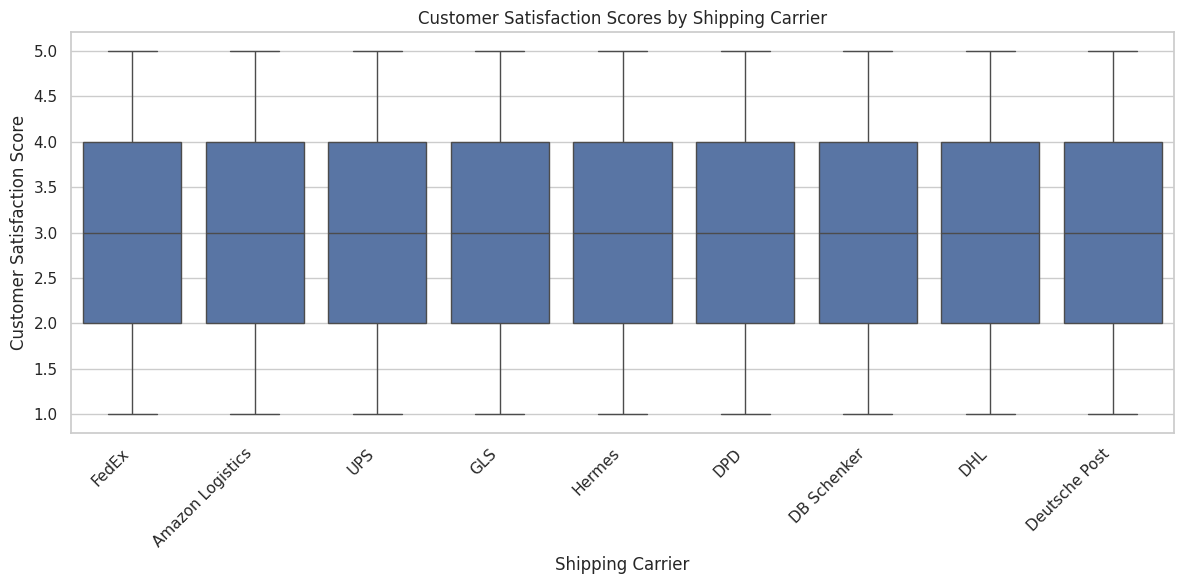

In [33]:
from scipy.stats import kruskal

satisfaction_by_carrier = df.dropna(
    subset=["customer_satisfaction_score"]
)

plt.figure(figsize=(12, 6))

sns.boxplot(
    data=satisfaction_by_carrier,
    x="carrier",
    y="customer_satisfaction_score"
)

plt.title("Customer Satisfaction Scores by Shipping Carrier")
plt.xlabel("Shipping Carrier")
plt.ylabel("Customer Satisfaction Score")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [34]:
carrier_satisfaction_summary = (
    satisfaction_by_carrier
    .groupby("carrier")["customer_satisfaction_score"]
    .agg(["count", "median", "mean", "std"])
    .sort_values("median", ascending=False)
)

display(carrier_satisfaction_summary)

carrier_groups = [
    group["customer_satisfaction_score"].values
    for _, group in satisfaction_by_carrier.groupby("carrier")
]

kruskal_result = kruskal(*carrier_groups)

print("Kruskal-Wallis Test: Satisfaction by Carrier")
print(f"H-statistic: {kruskal_result.statistic:.4f}")
print(f"P-value: {kruskal_result.pvalue:.6f}")

,count,median,mean,std
carrier,,,,
Amazon Logistics,2916,3.0,3.030521,1.404756
DB Schenker,3052,3.0,2.992792,1.434217
DHL,3010,3.0,2.983389,1.432562
DPD,3004,3.0,3.041944,1.410525
Deutsche Post,3112,3.0,3.000643,1.427561
FedEx,3020,3.0,2.996358,1.387848
GLS,3061,3.0,2.979745,1.410134
Hermes,3087,3.0,2.974409,1.403978
UPS,2973,3.0,3.081736,1.412921


Kruskal-Wallis Test: Satisfaction by Carrier
H-statistic: 15.0534
P-value: 0.058115


#### Findings: Customer Satisfaction by Shipping Carrier

The analysis examined whether customer satisfaction scores differed across the nine shipping carriers. The median satisfaction score was **3.0 for every carrier**, while mean scores ranged from approximately 2.97 to 3.08. The boxplots also showed very similar score distributions across carriers.

A Kruskal-Wallis test **found no statistically significant difference** in customer satisfaction across carriers (H = 15.0534, df = 8, p = 0.0581). **Although the p-value was relatively close to the 0.05 significance threshold, it did not meet the criterion for statistical significance.** Therefore, the analysis does not provide sufficient evidence that customer satisfaction differs across shipping carriers.

### Customer Satisfaction Across Shipment Statuses

This analysis examines whether customer satisfaction scores vary across shipment statuses. Comparing satisfaction across statuses may help identify whether completed, delayed, lost, or otherwise unresolved shipments are associated with different customer experiences. A Kruskal-Wallis test will be used because satisfaction scores are ordinal.

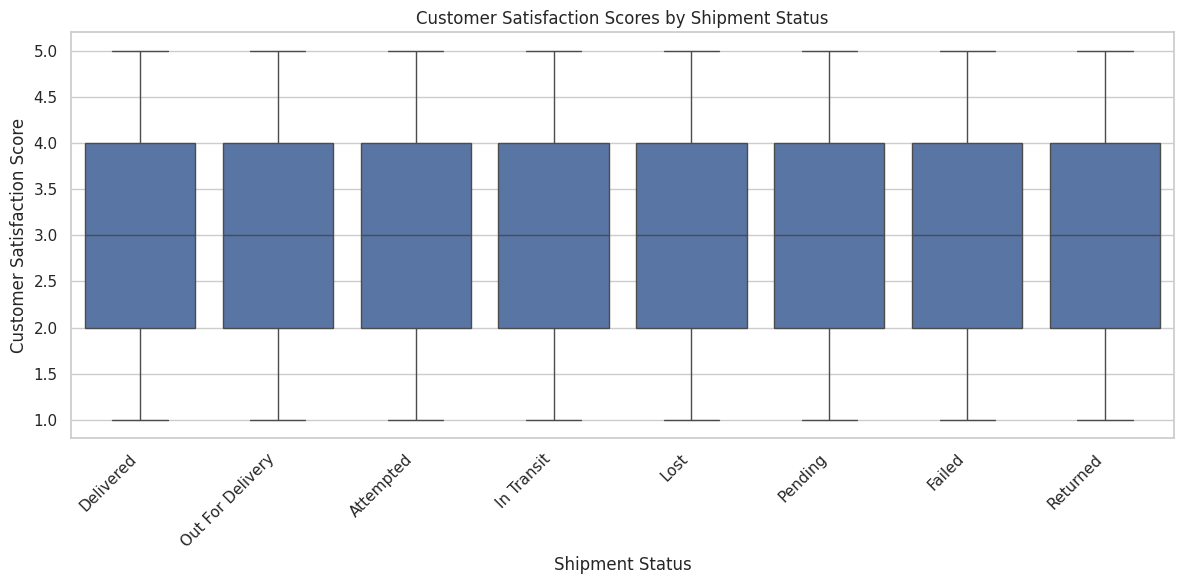

In [35]:
satisfaction_by_status = df.dropna(
    subset=["customer_satisfaction_score"]
)

plt.figure(figsize=(12, 6))

sns.boxplot(
    data=satisfaction_by_status,
    x="status",
    y="customer_satisfaction_score"
)

plt.title("Customer Satisfaction Scores by Shipment Status")
plt.xlabel("Shipment Status")
plt.ylabel("Customer Satisfaction Score")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [36]:
status_satisfaction_summary = (
    satisfaction_by_status
    .groupby("status")["customer_satisfaction_score"]
    .agg(["count", "median", "mean", "std"])
    .sort_values("median", ascending=False)
)

display(status_satisfaction_summary)

status_groups = [
    group["customer_satisfaction_score"].values
    for _, group in satisfaction_by_status.groupby("status")
]

status_kruskal = kruskal(*status_groups)

print("Kruskal-Wallis Test: Satisfaction by Shipment Status")
print(f"H-statistic: {status_kruskal.statistic:.4f}")
print(f"P-value: {status_kruskal.pvalue:.6f}")

,count,median,mean,std
status,,,,
Attempted,2652,3.0,2.983032,1.418506
Delivered,8236,3.0,3.003035,1.415969
Failed,2729,3.0,2.996336,1.427110
In Transit,2701,3.0,3.033321,1.407783
Lost,2663,3.0,3.011641,1.412970
Out For Delivery,2763,3.0,3.049222,1.399196
Pending,2716,3.0,3.006259,1.414330
Returned,2775,3.0,2.997117,1.414466


Kruskal-Wallis Test: Satisfaction by Shipment Status
H-statistic: 4.4923
P-value: 0.721649


#### Findings: Customer Satisfaction by Shipment Status

The analysis examined whether customer satisfaction scores differed across the eight shipment statuses. **All statuses had a median satisfaction score of 3.0, while mean scores ranged from approximately 2.98 to 3.05.** The boxplots also showed very similar distributions across the shipment statuses.

A Kruskal-Wallis test** found no statistically significant difference in customer satisfaction across shipment statuses** (H = 4.4923, df = 7, p = 0.7216). Therefore, the analysis does not provide sufficient evidence that customer satisfaction varies significantly according to shipment status.

### Customer Satisfaction Across Recorded Delay Reasons

This analysis examines whether customer satisfaction scores differ across recorded delay reasons. Only shipments with both an available satisfaction score and a recorded delay reason will be included. A Kruskal-Wallis test will be used to compare satisfaction score distributions across the delay-reason categories.

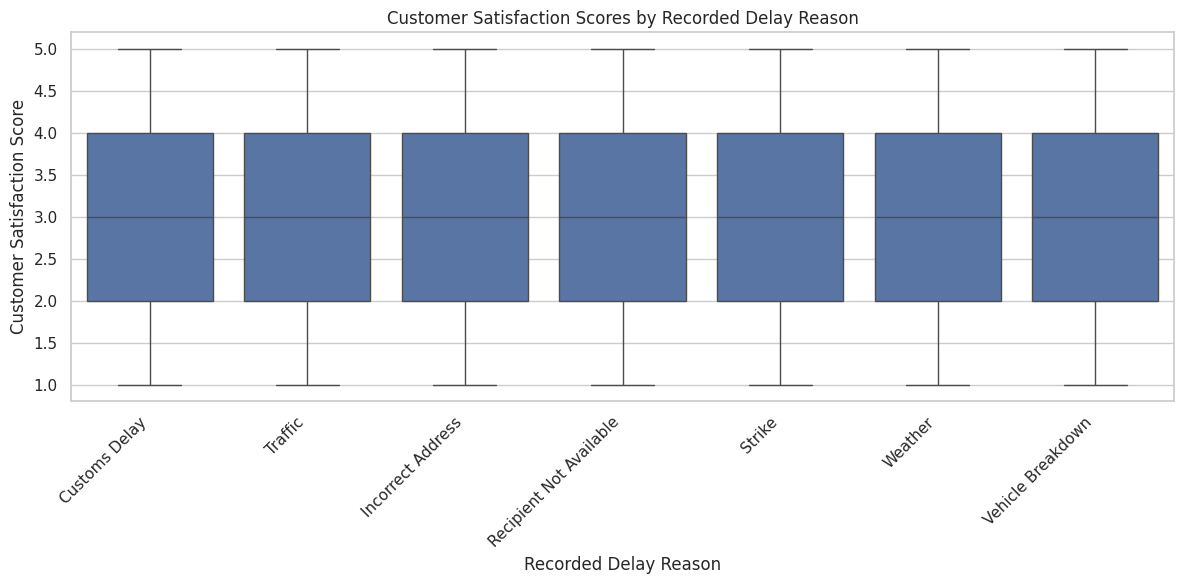

In [37]:
satisfaction_by_delay = df.dropna(
    subset=["customer_satisfaction_score", "delay_reason"]
)

plt.figure(figsize=(12, 6))

sns.boxplot(
    data=satisfaction_by_delay,
    x="delay_reason",
    y="customer_satisfaction_score"
)

plt.title("Customer Satisfaction Scores by Recorded Delay Reason")
plt.xlabel("Recorded Delay Reason")
plt.ylabel("Customer Satisfaction Score")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [38]:
delay_satisfaction_summary = (
    satisfaction_by_delay
    .groupby("delay_reason")["customer_satisfaction_score"]
    .agg(["count", "median", "mean", "std"])
    .sort_values("median", ascending=False)
)

display(delay_satisfaction_summary)

delay_groups = [
    group["customer_satisfaction_score"].values
    for _, group in satisfaction_by_delay.groupby("delay_reason")
]

delay_kruskal = kruskal(*delay_groups)

print("Kruskal-Wallis Test: Satisfaction by Delay Reason")
print(f"H-statistic: {delay_kruskal.statistic:.4f}")
print(f"P-value: {delay_kruskal.pvalue:.6f}")

,count,median,mean,std
delay_reason,,,,
Customs Delay,2882,3.0,3.044761,1.419753
Incorrect Address,2892,3.0,3.020055,1.423822
Recipient Not Available,3035,3.0,2.966722,1.418593
Strike,2976,3.0,3.016801,1.395932
Traffic,2944,3.0,3.047554,1.405216
Vehicle Breakdown,2976,3.0,3.006720,1.421783
Weather,2974,3.0,2.941157,1.410010


Kruskal-Wallis Test: Satisfaction by Delay Reason
H-statistic: 13.7621
P-value: 0.032410


#### Findings: Customer Satisfaction by Recorded Delay Reason

The analysis examined whether customer satisfaction scores differed across the seven recorded delay-reason categories. **All categories had a median satisfaction score of 3.0, while mean scores ranged from approximately 2.94 to 3.05. **The boxplots showed broadly similar distributions across categories.

A Kruskal-Wallis test produced an H-statistic of 13.7621 (df = 6) and a p-value of 0.0324. Before adjusting for multiple comparisons, **this result indicates a statistically significant difference in satisfaction score distributions across at least some delay-reason categories**. However, the differences in descriptive statistics were small. Furthermore, after applying a **Holm correction across the three RQ3 group comparisons conducted so far, the result does not remain statistically significant.** Therefore, the evidence for an association between recorded delay reason and customer satisfaction is not robust after accounting for multiple testing.

In [40]:
from statsmodels.stats.multitest import multipletests

rq3_pvalues = [
    kruskal_result.pvalue,  # Shipping carrier
    status_kruskal.pvalue,  # Shipment status
    delay_kruskal.pvalue    # Recorded delay reason
]

rq3_test_names = [
    "Shipping Carrier",
    "Shipment Status",
    "Recorded Delay Reason"
]

reject, adjusted_pvalues, _, _ = multipletests(
    rq3_pvalues,
    method="holm"
)

rq3_multiple_testing = pd.DataFrame({
    "comparison": rq3_test_names,
    "original_p_value": rq3_pvalues,
    "holm_adjusted_p_value": adjusted_pvalues,
    "significant_after_adjustment": reject
})

display(rq3_multiple_testing)

,comparison,original_p_value,holm_adjusted_p_value,significant_after_adjustment
0,Shipping Carrier,0.058115,0.116231,False
1,Shipment Status,0.721649,0.721649,False
2,Recorded Delay Reason,0.032410,0.097229,False


Multiple-Comparison Adjustment

The Holm correction was applied to the three Kruskal-Wallis tests examining customer satisfaction across shipping carriers, shipment statuses, and recorded delay reasons. **None of the comparisons remained statistically significant after adjustment, as all adjusted p-values exceeded 0.05**. Although recorded delay reason initially showed a statistically significant result, this finding was not robust after accounting for multiple testing. Overall, the categorical analyses do not provide sufficient evidence of differences in customer satisfaction across the groups examined.

### Customer Satisfaction and Numerical Shipment Characteristics

This analysis examines the relationships between customer satisfaction scores and numerical shipment characteristics, including distance, package weight, delivery attempts, shipping cost, and CO₂ emissions. Spearman's rank correlation will be used because customer satisfaction is measured on an ordinal scale. This method evaluates the direction and strength of monotonic relationships without assuming normally distributed variables.

In [41]:
from scipy.stats import spearmanr
from statsmodels.stats.multitest import multipletests

numeric_variables = [
    "distance_km",
    "package_weight_kg",
    "delivery_attempts",
    "shipping_cost_eur",
    "co2_emissions_kg"
]

satisfaction_correlations = []

for variable in numeric_variables:

    analysis_data = df[
        [variable, "customer_satisfaction_score"]
    ].dropna()

    rho, p_value = spearmanr(
        analysis_data[variable],
        analysis_data["customer_satisfaction_score"]
    )

    satisfaction_correlations.append({
        "variable": variable,
        "sample_size": len(analysis_data),
        "spearman_rho": rho,
        "p_value": p_value
    })

correlation_results = pd.DataFrame(satisfaction_correlations)

# Correct for multiple comparisons
reject, adjusted_pvalues, _, _ = multipletests(
    correlation_results["p_value"],
    method="holm"
)

correlation_results["holm_adjusted_p_value"] = adjusted_pvalues
correlation_results["significant_after_adjustment"] = reject

display(
    correlation_results.sort_values(
        "holm_adjusted_p_value"
    )
)

,variable,sample_size,spearman_rho,p_value,holm_adjusted_p_value,significant_after_adjustment
0,distance_km,27235,-0.003000,0.620494,1.0,False
1,package_weight_kg,27175,-0.007662,0.206573,1.0,False
2,delivery_attempts,27235,0.002784,0.645913,1.0,False
3,shipping_cost_eur,27200,-0.001879,0.756699,1.0,False
4,co2_emissions_kg,27235,-0.000923,0.878876,1.0,False


#### Findings: Customer Satisfaction and Numerical Shipment Characteristics

Spearman's rank correlation was used to examine the relationships between customer satisfaction and five numerical shipment characteristics: distance, package weight, delivery attempts, shipping cost, and CO₂ emissions.

The results showed **extremely weak correlations across all five variables.** Correlation coefficients ranged from -0.0077 to 0.0028, indicating negligible relationships with customer satisfaction. None of the correlations was statistically significant after applying the Holm correction for multiple comparisons. All adjusted p-values were 1.0000.

Overall, the results do not provide sufficient evidence of a meaningful monotonic relationship between the numerical shipment characteristics examined and customer satisfaction in this dataset.

## Overall Findings: Research Question 3

The third research question examined which factors are associated with customer satisfaction in logistics and supply chain operations. The analysis considered shipping carrier, shipment status, recorded delay reason, distance, package weight, delivery attempts, shipping cost, and CO₂ emissions.

The descriptive analysis showed that customer satisfaction scores were **relatively balanced across the five rating levels, with a mean of 3.01 and a median of 3.00.** However, approximately **46.60% of satisfaction scores were missing, meaning that the analysis was limited to the 27,235 shipments with available scores.**

The categorical analyses found no statistically significant differences in customer satisfaction across shipping carriers or shipment statuses. Although the initial Kruskal-Wallis test for recorded delay reason produced a p-value of 0.0324, this result did not remain statistically significant after applying the Holm correction for multiple comparisons.

The numerical analysis also found no statistically significant relationships between customer satisfaction and distance, package weight, delivery attempts, shipping cost, or CO₂ emissions. All Spearman correlation coefficients were close to zero, and none remained significant after the Holm adjustment.

Overall, **the analysis does not provide sufficient statistical evidence that the operational and transportation-related factors examined are meaningfully associated with customer satisfaction in this dataset.** However, this does not establish that these factors have no influence on customer experience.

An **important limitation is the substantial proportion of missing satisfaction scores**. If the missing scores are systematically related to shipment characteristics or customer experiences, **the observed results may not fully represent all shipments.** Consequently, the findings should be interpreted with caution and should not be generalized beyond the available satisfaction responses without further investigation.

In [42]:
from scipy.stats import chi2_contingency

df["satisfaction_missing"] = (
    df["customer_satisfaction_score"].isna()
)

for variable in ["carrier", "status"]:

    table = pd.crosstab(
        df[variable],
        df["satisfaction_missing"]
    )

    chi2, p_value, dof, expected = chi2_contingency(table)

    missing_rates = (
        df.groupby(variable)["satisfaction_missing"]
        .mean()
        .mul(100)
        .round(2)
    )

    print(f"\nMissing satisfaction scores by {variable}:")
    display(missing_rates.rename("missing_percentage").to_frame())

    print(f"Chi-square p-value: {p_value:.4f}")


Missing satisfaction scores by carrier:


,missing_percentage
carrier,
Amazon Logistics,47.09
DB Schenker,46.01
DHL,46.19
DPD,47.30
Deutsche Post,46.23
FedEx,46.97
GLS,46.70
Hermes,45.94
UPS,46.97


Chi-square p-value: 0.7820

Missing satisfaction scores by status:


,missing_percentage
status,
Attempted,46.85
Delivered,46.43
Failed,46.87
In Transit,47.79
Lost,47.51
Out For Delivery,45.78
Pending,46.72
Returned,45.16


Chi-square p-value: 0.1527


#### Assessment of Missing Customer Satisfaction Scores

A final assessment examined whether missing customer satisfaction scores varied across shipping carriers and shipment statuses. **The chi-square tests found no statistically significant associations between missingness and shipping carrier (p = 0.7820) or shipment status (p = 0.1527). Missing percentages were relatively consistent across both groups.** Although this reduces concern that missing satisfaction scores are strongly concentrated within particular carriers or shipment statuses, it does not establish that the missing data are completely random. The substantial overall missingness of 46.60% remains an important limitation when interpreting the findings.

# Overall Exploratory Data Analysis Conclusions

This exploratory data analysis examined logistics and supply chain operations through three research questions.

### Research Question 1: Delivery Performance Across Shipping Carriers

**The analysis found no statistically significant association between shipping carrier and delivery status (p = 0.6950).** Although Hermes had the highest delivered-status rate and DPD the lowest, the difference was relatively small. The r**esults do not provide sufficient evidence that delivery outcomes differ meaningfully across carriers**.

### Research Question 2: Factors Associated with Delivery Delays

The analysis examined recorded delay reasons, shipment status, shipping carrier, shipment type, distance, package weight, delivery attempts, shipping cost, and CO₂ emissions. **No statistically significant relationships were identified in the tests conducted**. However, **mixed and ambiguous date formats prevented reliable calculation of delivery duration and actual lateness. **Consequently, the findings relate to recorded delay reasons and shipment status rather than directly measured delivery delays.

### Research Question 3: Factors Associated with Customer Satisfaction

**Customer satisfaction scores were centered around 3.0**. **No statistically significant differences** remained across shipping carriers, shipment statuses, or recorded delay reasons after multiple-comparison adjustment. Similarly, no meaningful correlations were identified between satisfaction and the numerical shipment characteristics examined. **Approximately 46.60% of satisfaction scores were missing, which remains an important limitation.**

### Overall Conclusion

Across the three research questions, **the analysis did not identify strong or statistically significant relationships between the available operational and transportation-related variables and delivery outcomes or customer satisfaction**. These findings should not be interpreted as proof that the examined factors have no influence. Rather, they reflect the relationships detectable using the available data and measures.

**Several data limitations affect the interpretation of the results, particularly ambiguous delivery dates and missing customer satisfaction scores. **Future analysis could benefit from more reliable delivery timestamps, complete customer feedback, and additional operational information.

Overall, this EDA provides an initial understanding of the dataset, identifies important data-quality limitations, and **establishes a foundation for further analysis and visualization.**

### Additional Limitation: Synthetic Dataset

An important consideration when interpreting these findings is that the dataset used in this project is **synthetically generated rather than collected from actual logistics and supply chain operations.** Consequently, the distributions, relationships, and patterns observed may reflect the assumptions or processes used to generate the data rather than real-world operational conditions. For example, **the relatively balanced satisfaction scores and the lack of statistically significant relationships across several variables may be characteristics of the synthetic dataset.** Although the analysis demonstrates exploratory data analysis techniques and provides insights into the structure of the available data, the findings should not be treated as definitive evidence of real-world logistics performance or customer behavior. **Further research using actual operational data would be necessary to validate these observations.**